=== PHÂN PHỐI BIẾN MỤC TIÊU (CHURN) ===
       Số lượng khách hàng (Count)  Tỷ lệ phần trăm (%)
Churn                                                  
No                            5174                73.46
Yes                           1869                26.54


C:\Users\PC\AppData\Local\Temp\ipykernel_3484\2474223507.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


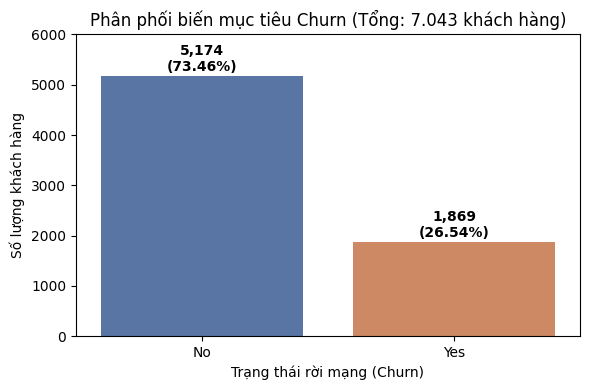

In [3]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
# import tương đương #include của c++, as là bí danh giống sql

df = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
counts = df['Churn'].value_counts()
percentages = df['Churn'].value_counts(normalize=True) * 100

churn_table = pd.DataFrame({
    'Số lượng khách hàng (Count)': counts,
    'Tỷ lệ phần trăm (%)': percentages.round(2)
})
# DataFrame là bảng 2 chiều, Series (kết quả của .value_counts) là mảng 1 chiều

print("=== PHÂN PHỐI BIẾN MỤC TIÊU (CHURN) ===")
print(churn_table)

plt.figure(figsize=(6, 4))
ax = sns.barplot(
    x=churn_table.index, 
    y=churn_table['Số lượng khách hàng (Count)'], 
    palette=['#4C72B0', '#DD8452']
)

# Hiển thị con số và tỷ lệ % trực tiếp trên đỉnh mỗi cột
for i, (count, pct) in enumerate(zip(churn_table['Số lượng khách hàng (Count)'], churn_table['Tỷ lệ phần trăm (%)'])):
    ax.text(i, count + 100, f"{count:,}\n({pct}%)", ha='center', fontweight='bold')

plt.title('Phân phối biến mục tiêu Churn (Tổng: 7.043 khách hàng)')
plt.xlabel('Trạng thái rời mạng (Churn)')
plt.ylabel('Số lượng khách hàng')
plt.ylim(0, 6000)
plt.tight_layout()
plt.show()


In [4]:
df.info()
# Đây là lệnh đầu tiên phải thực thi để kiểm tra dữ liệu

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


# KIỂM THỬ: Cột TotalCharges bị sai kiểu dữ liệu (object thay vì float)
# NGUYÊN NHÂN: Đối với các khách hàng mới cột TotalCharges sẽ là dấu " ".

In [5]:
# Tìm lỗi sai kiểu dữ liệu TotalCharges

temp_num = pd.to_numeric(df['TotalCharges'], errors='coerce')
error_rows = df[temp_num.isna() & df['TotalCharges'].notna()]
print(f"Tìm thấy {len(error_rows)} dòng lỗi.")

unique_errors = error_rows['TotalCharges'].unique()
for val in unique_errors:
    print("Giá trị lỗi cụ thể là:", repr(val), "| Độ dài chuỗi:", len(val))

print(error_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

# Sửa lỗi sai kiểu dữ liệu TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)

Tìm thấy 11 dòng lỗi.
Giá trị lỗi cụ thể là: ' ' | Độ dài chuỗi: 1
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


In [11]:
# Kiểm tra rò rỉ dữ liệu
df = df.drop(columns=['customerID'], errors='ignore')

# KIỂM THỬ: Cột customerID không mang thông tin dự báo hành vi rời mạng
# XỬ LÝ: Đã loại cột customerID khỏi tập

In [ ]:
# Xóa cột customerID
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])
    print("Đã loại bỏ cột định danh: 'customerID'")
else:
    print("Cột 'customerID' đã được loại bỏ trước đó.")

In [6]:
# Rà soát các cột phát sinh hậu nghiệm (Do chỉ được phép dùng các dữ liệu tồn tại trước.)
leakage_candidates = [ 'Churn Score', 'CLTV', 'Churn Reason', 'Churn Label', 'Churn Value' ]

found_leakage_cols = []

for col in leakage_candidates:
    if col in df.columns:
        found_leakage_cols.append(col)

if found_leakage_cols: 
    df = df.drop(columns=found_leakage_cols)
    print(f"Đã phát hiện và loại bỏ các cột rò rỉ hậu nghiệm: {found_leakage_cols}")
else:
    print("Không phát hiện cột hậu nghiệm (Churn Score, CLTV, Churn Reason...) trong tập dữ liệu.")

Không phát hiện cột hậu nghiệm (Churn Score, CLTV, Churn Reason...) trong tập dữ liệu.
